# Model-based gate: does a PFN-only lookahead find the headroom over EI?

## Description

<!-- Written 2026-11-11 before the first run (pre-registration). Design: research_log/decisions/0003 §8.3–8.4. Issue #13. -->

**Question.** The api_round1 pilot (notebook 06) found sizeable *clairvoyant* headroom over EI's pick: the cross-fitted best of 16 labeled candidates gains 0.70 [0.57, 0.84] % of the gap per state, against EI's final regret of 1.34. The learned head could not exploit it.

Here is the cheaper and sharper question first: does a lookahead that uses **only the PFN** recognise which candidate beats EI's pick? The lookahead is a one-step improvement whose continuations are simulated from the PFN's own predictive. Such a policy is deployable, though expensive. Its gain bounds what amortizing it (the value head / decoder) can reach without ground truth. If it finds nothing, the headroom isn't visible from the belief, and amortized policy iteration on this prior has little to gain from the PFN state.

**Setup.**
- *Belief continuation* (`experimental/api_gate.py`): from state (D, t), query the candidate, draw its y from the PFN's posterior predictive, follow EI to T with every y drawn from the PFN given the fantasized data, and record the best y.
  - 4 continuations per candidate.
  - Nuisance (candidate sets, fantasy uniforms) is shared across candidates, so the comparison uses common random numbers.
  - The replicate ids are disjoint from those of the ground-truth labels, so the model's choice shares no luck with the label that scores it.
- *Stage 1a (states).* On the first 2000 labeled states of `api_round1/pilot_20261111-133311` (split 4, d = 2), score the same 16 candidates per state.
  - Select the best model advantage (x₀ if none > 0), without the task.
  - Score the selected candidate with its *ground-truth* label (the mean over 4 true-task continuations).
  - Mean over states: G = a deployable, first-order per-state gain.
  - References: the clairvoyant cross-fitted best (0.70 on all 4000 states; recomputed here on the same 2000), and a random valid candidate (null: deviation without information).
- *Stage 1b (policy).* The model-based rollout policy against EI on 200 split-1 tasks, paired (common random numbers), d = 2, n_init = 4, T = 20.
  - At every step: the round-1 candidate set, the same 16-candidate choice rule, 4 belief continuations each.
  - Query the best candidate if its model advantage is > 0, otherwise EI's pick.

**What to look for.**
1. Stage 1b: the paired Δ = mean_task [R(mb) − R(EI)] in % of the gap, with bootstrap 95% CI, and the deviation rate.
2. Stage 1a:
   - G and its CI, as a share of the clairvoyant reference;
   - G at stricter thresholds (model advantage > τ·se, τ ∈ {1, 2}), secondary;
   - the within-state Spearman between model and true advantage;
   - G by branch step t.

**GO / NO-GO** (rule `analysis/api.py::gate_verdict`, on Stage 1b, worthwhile = 5% relative):
- **GO**: the model-based policy lowers mean normalized regret by ≥ 5% with the CI of Δ below 0.
- **NO-GO**: the CI rules out a 5% gain.
- **INCONCLUSIVE**: otherwise.

GO means the PFN's belief carries the planning information, so amortizing it is worthwhile. Then the readout probes (notebook 08) ask *where* in the PFN state it sits, and the 0006 decoder tries to learn it. NO-GO with Stage 1a G ≈ 0 means the headroom of notebook 06 is invisible to the PFN's own belief. It is then PFN error or luck, not plannable from the belief, and fine-tuning the PFN on BO contexts (0004/0005, E1) becomes the more promising lever.

**Limits.**
- Noise-free P0, d = 2, T = 20 only. `pfn_large` is valid for n ≤ 100; contexts here have n ≤ 24.
- Belief continuations sample marginals step by step, re-encoding after each sample: the PFN's posterior predictive process, not a joint sample.
- 16 candidates per decision and 4 continuations: a cheap ceiling. A larger candidate set or more continuations could find more.
- 200 test tasks is a pilot size.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.api import gate_verdict, paired_delta
from anytime_acq.analysis.stats import bootstrap_ci
from anytime_acq.tasks.api_gate import selected_gain

SNAPSHOT = "/home/ruhkopf/PycharmProjects/anytime-acquisition-api/results/api_gate/pilot_20261111-164326"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=api_gate task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261111-164326` |
| commit | `5ce73d21063f` (tag `sweep/api_gate/pilot_20261111-164326`) |
| backend / host | detached / ulysses |
| ran | 2026-11-11T16:43:29 → 2026-11-11T20:40:39 |
| members | 1: 1 done |
| compute | 4.0 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/api_gate.yaml`):

```yaml
# @package _global_
# Model-based gate (research_log/decisions/0003 §8.3, Stages 1a + 1b): does a PFN-only lookahead find the
# headroom over EI? Pre-registration: notebooks/07_2026-11-11_api_gate.ipynb.
# Stage 1a on the first 2000 labeled states of api_round1's pilot (split 4); Stage 1b on 200 split-1 tasks.
defaults:
  - override /task: api_gate

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  api_candidates.local_sigmas: '[0.01, 0.03, 0.1]'
  api_candidates.n_global: 64
  api_candidates.n_local_per_point: 16
  api_candidates.n_top: 4
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  eps: 0.0001
  labels.path: api_round1/pilot_20261111-133311/0/tracking/artifacts/labels.pt
  labels.sha256: c27d893923d0f003ed7b1e1148ad6670c1f5fb061ac7cdf137eb2a8a64c678d9
  n_init_per_d: 2
  name: api_gate
  pfn: pfn_large
  policy.n_cont: 4
  policy.n_labeled: 16
  policy.n_tasks: 200
  policy.rep_offset: 100
  policy.split: 1
  policy.task_offset: 0
  states.n_cont: 4
  states.n_states: 2000
  states.rep_base: 100
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tf32: false
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
print("minutes:", {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
gs, test, dec, best = snap.table("gate_states"), snap.table("test"), snap.table("decisions"), snap.table("best")
print("states:", gs.state.nunique(), "| test tasks:", test.task.nunique(), "| arms:", sorted(test.arm.unique()))

member status: {'DONE': 1}
minutes: {'time/policy_s': 160.7, 'time/states_s': 76.5}
states: 2000 | test tasks: 200 | arms: ['ei', 'mb']


## 1. Stage 1a: candidates selected by belief continuations, scored by ground truth

Per state, the candidate with the best model-based advantage (belief continuations, no access to the task) is chosen if that advantage exceeds τ·se, otherwise x₀.
The table gives the mean ground-truth label of the choice (% of the gap; positive = better than EI's pick), with a bootstrap CI over states.
For reference: the clairvoyant cross-fitted headroom at round 1's states was 0.70 [0.57, 0.84] (notebook 06).

,tau,gain,lo,hi,deviation_rate,share_worse,share_better
0,0.0,0.080,-0.023,0.193,0.872,0.316,0.274
1,0.5,0.103,-0.005,0.220,0.801,0.285,0.256
2,1.0,0.136,0.004,0.289,0.646,0.235,0.208
3,2.0,0.008,-0.032,0.049,0.248,0.092,0.085
4,3.0,0.005,-0.013,0.023,0.094,0.032,0.033


/home/ruhkopf/PycharmProjects/anytime-acquisition-api/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


within-state Spearman(model advantage, label): 0.042 [0.026, 0.057] over 1526 states


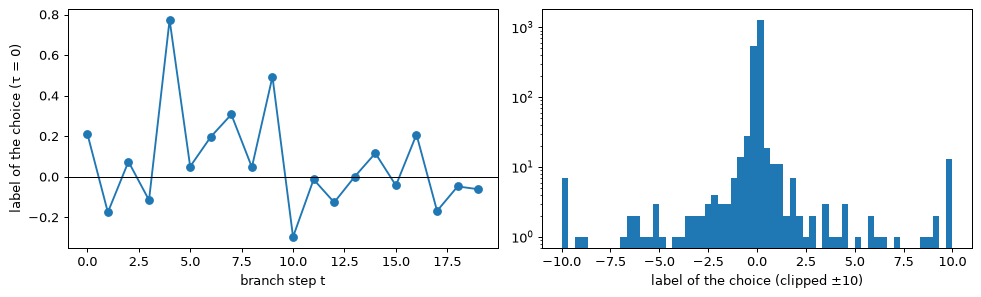

In [ ]:
rows = []
for tau in (0.0, 0.5, 1.0, 2.0, 3.0):
    sel = selected_gain(gs, tau)
    lo, hi = bootstrap_ci(sel.adv_true.to_numpy())
    rows.append({"tau": tau, "gain": sel.adv_true.mean(), "lo": lo, "hi": hi, "deviation_rate": (sel.j > 0).mean(),
                 "share_worse": (sel.adv_true < 0).mean(), "share_better": (sel.adv_true > 0).mean()})
display(pd.DataFrame(rows).round(3))
v = gs.loc[gs.valid & (gs.j > 0)]
rho = v.groupby("state").apply(lambda d: d.adv_model.corr(d.adv_true, method="spearman"), include_groups=False)
lo, hi = bootstrap_ci(rho.dropna().to_numpy())
print(f"within-state Spearman(model advantage, label): {rho.mean():.3f} [{lo:.3f}, {hi:.3f}] over {rho.notna().sum()} states")
sel = selected_gain(gs, 0.0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
sel.groupby("t").adv_true.mean().plot(ax=ax[0], marker="o"); ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("branch step t"); ax[0].set_ylabel("label of the choice (τ = 0)")
ax[1].hist(np.clip(sel.adv_true, -10, 10), bins=60); ax[1].set_yscale("log"); ax[1].set_xlabel("label of the choice (clipped ±10)")
plt.tight_layout(); plt.show()

## 2. Stage 1b: the model-based rollout policy against EI (paired, CRN)

,a,b,n,delta,lo,hi,ref_mean,rel,rel_lo,rel_hi,frac_a_better,frac_tied
mb − ei (norm_regret),mb,ei,200,0.028074,-0.580841,0.739424,1.513124,0.018554,-0.383869,0.488674,0.395,0.18


,a,b,n,delta,lo,hi,ref_mean,rel,rel_lo,rel_hi,frac_a_better,frac_tied
mb − ei (log_regret),mb,ei,200,-0.018988,-0.095192,0.05594,-3.494573,0.005434,0.02724,-0.016008,0.395,0.18


deviation rate: 0.86


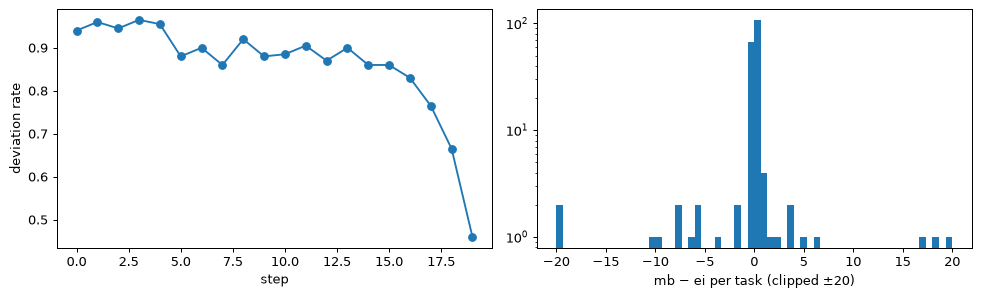

In [ ]:
d = paired_delta(test, "mb", "ei")
display(pd.Series(d).to_frame("mb − ei (norm_regret)").T.round(4))
dl = paired_delta(test, "mb", "ei", col="log_regret")
display(pd.Series(dl).to_frame("mb − ei (log_regret)").T.round(4))
print("deviation rate:", round(float(dec.deviated.mean()), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
dec.groupby("step").deviated.mean().plot(ax=ax[0], marker="o"); ax[0].set_ylabel("deviation rate"); ax[0].set_xlabel("step")
g = test.pivot_table(index="task", columns="arm", values="norm_regret")
ax[1].hist(np.clip(g.mb - g.ei, -20, 20), bins=60); ax[1].set_yscale("log"); ax[1].set_xlabel("mb − ei per task (clipped ±20)")
plt.tight_layout(); plt.show()

## Observations (pilot, snapshot `results/api_gate/pilot_20261111-164326`)

Written after the run.
- **Stage 1b (the decision).**
  - The model-based rollout policy is indistinguishable from EI: Δ norm_regret = +0.028 [−0.58, 0.74] on 200 split-1 tasks, relative +1.9% [−38%, +49%].
  - It deviates from EI's pick at 86% of the steps, wins on 39.5% of the tasks and ties on 18%.
  - The CI is far too wide for either GO or NO-GO, so the verdict is **INCONCLUSIVE**.
  - Bootstrap note: the log_regret row's `rel` bounds look swapped because its reference mean is negative. It is not used for the decision.
- **Stage 1a: the belief barely ranks the candidates.**
  - Choosing by model advantage (τ = 0) gains G = 0.080 [−0.025, 0.19] % of the gap per state over 2000 states.
  - For comparison:
    - a random valid deviation gains 0.035 [−0.019, 0.088];
    - the in-sample best of the 16 gains 0.89 [0.71, 1.10]. This is upward-biased; the cross-fitted value at round 1's states was 0.70.
  - So the model captures roughly a tenth of the clairvoyant headroom, and is not clearly better than deviating at random.
  - The within-state Spearman between model advantage and true label is 0.042 [0.026, 0.057]. It is significant but tiny, and matches the probes' adv result (notebook 08: ≤ 0.025 from every input).
  - The τ = 1 threshold gives 0.136 [0.004, 0.289], the only CI above 0. It is a secondary threshold out of three, chosen after seeing the data, so it is not evidence.
  - By branch step (computed from `tables/gate_states.parquet`), G is concentrated early:
    - t ≤ 4: 0.17 ± 0.15 (se);
    - t 5–9: 0.22 ± 0.12;
    - t ≥ 10: about 0 (−0.06 and −0.02).
- **Reading.** The pre-registered reading of "G ≈ 0" applies in substance: the headroom of notebook 06 is mostly not visible to the PFN's own belief continuations at this candidate and continuation budget. It is PFN error or luck rather than plannable from the belief. This points to the 0004/0005 E1 lever (fine-tuning the PFN on BO contexts) rather than to amortizing a belief-only lookahead. The 0006 decoder (notebook 09) is still the direct test of whether a model trained on ground-truth labels can do better.


## Verdict

In [ ]:
print("verdict (analysis/api.py::gate_verdict, Stage 1b):", gate_verdict(d))

verdict (analysis/api.py::gate_verdict, Stage 1b): INCONCLUSIVE
